# 05 · Ward-hour demand forecasting

**Synthetic, and accuracy here is NOT a research claim.** The training data comes from this project's own incident generator (`configs/incidents.yaml`), whose intensity is a formula we wrote, so a model handed those same inputs recovers it by construction. The research claim is only how dispatch performance depends on forecast quality, which phase 10 sweeps using these models as its quality levels (D-030).

Produced by `make forecast` → `results/forecasting/`. This notebook only reads those files.

Why the usual metric is useless here: **99.6 % of ward-hour cells are empty**, so mean absolute error rewards predicting zero everywhere. Poisson deviance, calibration and the top-k ward hit rate carry the information, and the last is what pre-positioning actually asks.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from resqcity.common.config import PROJECT_ROOT

RESULTS = PROJECT_ROOT / 'results' / 'forecasting'
report = json.loads((RESULTS / 'metrics_synthetic.json').read_text(encoding='utf-8'))
calib = pd.read_csv(RESULTS / 'calibration_synthetic.csv')
metrics = pd.DataFrame(report['metrics']).set_index('model')
cols = ['poisson_deviance', 'poisson_deviance_daily', 'mae',
        'top_3_ward_hit_rate', 'top_5_ward_hit_rate', 'top_10_ward_hit_rate',
        'observed', 'predicted']
metrics[cols].style.format('{:.5g}')

,poisson_deviance,poisson_deviance_daily,mae,top_3_ward_hit_rate,top_5_ward_hit_rate,top_10_ward_hit_rate,observed,predicted
model,,,,,,,,
uniform,0.017988,0.22582,0.0026996,0.048286,0.083052,0.18252,2071,2038.1
climatology,0.017937,0.20286,0.0026947,0.14486,0.22694,0.38194,2071,2038.1
lightgbm_realistic,0.016591,0.19508,0.0027142,0.14196,0.2197,0.36214,2071,2067.3
lightgbm_informed,0.016614,0.19537,0.0027144,0.13761,0.21632,0.36456,2071,2067.9
oracle,0.016425,0.19419,0.0027005,0.16948,0.23708,0.38339,2071,2047.2
lightgbm_realistic+noise0.5,0.016931,0.19558,0.0027144,0.12892,0.19218,0.33221,2071,2067.6
lightgbm_realistic+noise1,0.017952,0.19773,0.0027148,0.098503,0.155,0.27861,2071,2067.8


`oracle` is the generator's own intensity — a declared ground-truth ablation, the best any forecaster could do, never an achievable result. `uniform` is the no-information floor. The two LightGBM rows differ only in what they are allowed to see.

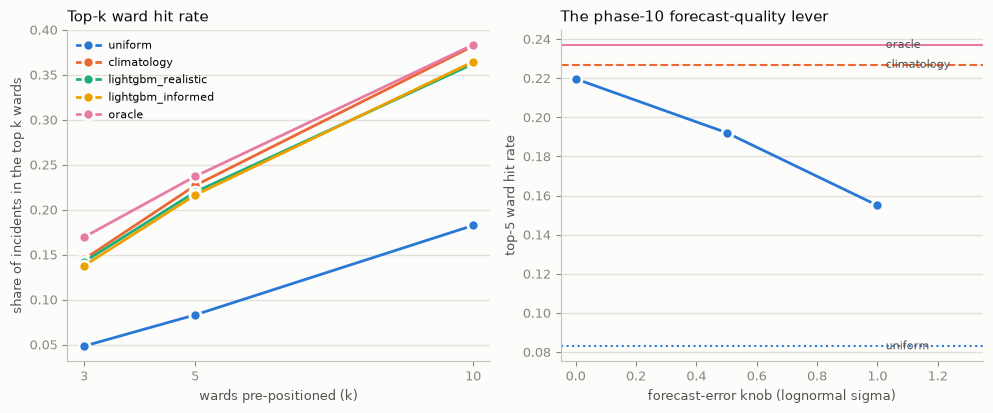

In [2]:
# Palette: reference categorical slots (validated light-mode set), text and grid neutrals.
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6']
SURFACE, TEXT, TEXT2, MUTED, GRID, AXIS = ('#fcfcfb', '#0b0b0b', '#52514e', '#898781',
                                          '#e1e0d9', '#c3c2b7')
plt.rcParams.update({'font.size': 9, 'axes.edgecolor': AXIS, 'axes.labelcolor': TEXT2,
                     'xtick.color': MUTED, 'ytick.color': MUTED,
                     'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE})
order = ['uniform', 'climatology', 'lightgbm_realistic', 'lightgbm_informed', 'oracle']
colour = dict(zip(order, SERIES))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
ks = [3, 5, 10]
ax = axes[0]
for name in order:
    ys = [metrics.loc[name, f'top_{k}_ward_hit_rate'] for k in ks]
    ax.plot(ks, ys, marker='o', ms=8, lw=2, color=colour[name],
            markeredgecolor=SURFACE, markeredgewidth=2, label=name)
ax.set_xticks(ks)
ax.legend(frameon=False, fontsize=8, loc='upper left')  # 5 series: legend, not labels
ax.set_xlabel('wards pre-positioned (k)')
ax.set_ylabel('share of incidents in the top k wards')
ax.set_title('Top-k ward hit rate', loc='left', color=TEXT)
ax.set_xlim(2.7, 10.3)

noise = [m for m in report['metrics'] if 'noise' in m['model']]
ax = axes[1]
sigmas = [0.0] + [float(m['model'].split('noise')[1]) for m in noise]
ys = [metrics.loc['lightgbm_realistic', 'top_5_ward_hit_rate']] + [
    m['top_5_ward_hit_rate'] for m in noise]
ax.plot(sigmas, ys, marker='o', ms=8, lw=2, color=SERIES[0],
        markeredgecolor=SURFACE, markeredgewidth=2)
for name, style in (('oracle', '-'), ('climatology', '--'), ('uniform', ':')):
    y = metrics.loc[name, 'top_5_ward_hit_rate']
    ax.axhline(y, color=colour[name], lw=1.5, ls=style)
    ax.annotate(name, (max(sigmas), y), xytext=(6, 0), textcoords='offset points',
                va='center', color=TEXT2, fontsize=8)
ax.set_xlabel('forecast-error knob (lognormal sigma)')
ax.set_ylabel('top-5 ward hit rate')
ax.set_title('The phase-10 forecast-quality lever', loc='left', color=TEXT)
ax.set_xlim(-0.05, max(sigmas) * 1.35)
for a in axes:
    a.grid(axis='y', color=GRID, lw=1)
    a.set_axisbelow(True)
    for side in ('top', 'right'):
        a.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

The left panel is the one that matters for phase 6: if you can stand units in only a few wards, how many of the next hour's incidents are you standing near?

The right panel is why the noise knob exists. The *models* span a narrow band, so without an explicit error knob phase 10 would have almost no lever to pull.

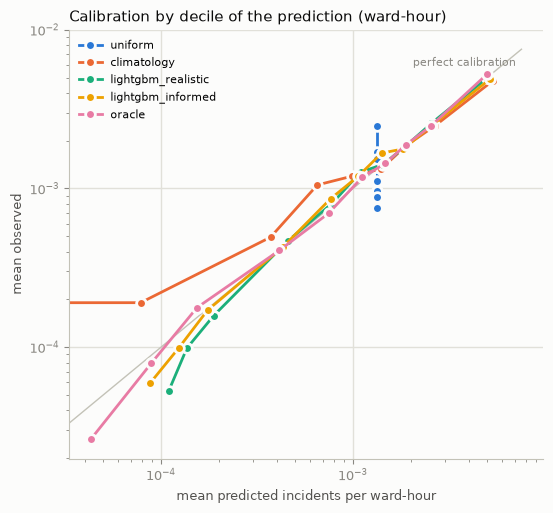

model,climatology,lightgbm_informed,lightgbm_realistic,lightgbm_realistic+noise0.5,lightgbm_realistic+noise1,oracle,uniform
decile,,,,,,,
1,0.00016,0.00006,0.00005,0.00009,0.00014,0.00003,0.00246
2,0.00009,0.00010,0.00010,0.00013,0.00024,0.00008,0.00137
3,0.00019,0.00017,0.00016,0.00020,0.00043,0.00018,0.00137
4,0.00049,0.00043,0.00047,0.00055,0.00064,0.00041,0.00146
5,0.00105,0.00086,0.00082,0.00101,0.00108,0.00070,0.00076
6,0.00120,0.00120,0.00127,0.00115,0.00142,0.00118,0.00097
7,0.00133,0.00167,0.00141,0.00164,0.00158,0.00144,0.00089
8,0.00187,0.00178,0.00180,0.00197,0.00220,0.00187,0.00170
9,0.00249,0.00249,0.00257,0.00260,0.00245,0.00247,0.00111


In [3]:
ward_hour = calib[calib['scale'] == 'ward_hour']
fig, ax = plt.subplots(figsize=(5.6, 5.2))
lo = min(ward_hour['mean_predicted'].min(), ward_hour['mean_observed'].min())
hi = max(ward_hour['mean_predicted'].max(), ward_hour['mean_observed'].max())
ax.plot([lo, hi], [lo, hi], color=AXIS, lw=1, zorder=1)
ax.annotate('perfect calibration', (hi, hi), xytext=(-4, -12),
            textcoords='offset points', ha='right', color=MUTED, fontsize=8)
for name in order:
    part = ward_hour[ward_hour['model'] == name]
    ax.plot(part['mean_predicted'], part['mean_observed'], marker='o', ms=7, lw=2,
            color=colour[name], markeredgecolor=SURFACE, markeredgewidth=2, label=name)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('mean predicted incidents per ward-hour')
ax.set_ylabel('mean observed')
ax.set_title('Calibration by decile of the prediction (ward-hour)', loc='left',
             color=TEXT)
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.grid(color=GRID, lw=1)
ax.set_axisbelow(True)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()
ward_hour.pivot(index='decile', columns='model',
                values='mean_observed').round(5)

## What to take from this

- The **climatology baseline is strong** once its hour-of-week shape is pooled across wards. A per-cell historical average is degenerate at this sparsity (it predicts exactly zero for 91 % of cells), so pooling is what makes it a fair comparison rather than a strawman.
- **Being handed the generator's own inputs buys almost nothing**: the `informed` model does not beat `realistic`. The circularity this phase was designed around turned out to be small, because the generator's rain effect is weak and ward identity is available to both models.
- The gap from no information to perfect knowledge is **narrow**, so phase 10 should lean on the explicit error knob rather than on the differences between these models.
- None of this says anything about forecasting real Pune demand. It says what a forecaster can recover from this generator, which is the only thing the simulator needs.